# SPRINT 3: OPTIMIZATION AND FINAL MODEL

## 1. Importing Required Libraries

In this sprint, we will optimize the baseline Decision Tree model using feature engineering, feature selection, and hyperparameter tuning.

We will also evaluate the optimized model and compare its performance with the baseline model.

In [3]:
# Import required libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

warnings.filterwarnings("ignore")

# SMOTE for handling imbalanced data
from imblearn.over_sampling import SMOTE

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Hyperparameter tuning
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import sys

print("Python executable:", sys.executable)

Python executable: e:\Innomatics\ML_Innomatics\BANK_MARKET_CAMPAIGN_PREDICTION\.venv\Scripts\python.exe


In [28]:
# Load baseline models from Sprint 2

import joblib

baseline_models = joblib.load(
    "../models/sprint2_baseline_models.pkl"
)

# Select baseline Random Forest
rf_model = baseline_models["random_forest"]

# Generate predictions
rf_test_pred = rf_model.predict(X_test)

print("Baseline Random Forest loaded successfully!")
print("Predictions generated successfully!")

Baseline Random Forest loaded successfully!
Predictions generated successfully!


In [5]:
# Step 7: Load processed training and testing datasets

train_df = pd.read_csv("../data/processed/train_processed.csv")
test_df = pd.read_csv("../data/processed/test_processed.csv")

# Display dataset dimensions
print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

# Display first five rows
display(train_df.head())

Training Dataset Shape: (36168, 52)
Testing Dataset Shape: (9043, 52)


,age,balance,day,campaign,pdays,previous,previously_contacted,job_admin.,job_blue-collar,job_entrepreneur,...,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown,y
0,-0.463826,-0.062807,1.582124,-0.245119,-0.410910,0.0,-0.471755,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
1,-1.617412,2.146006,-1.298384,1.004857,1.446096,0.0,2.119745,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1
2,0.305232,-0.586246,-0.458236,1.004857,-0.410910,0.0,-0.471755,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1
3,0.689761,-0.793246,1.822166,2.254833,-0.410910,0.0,-0.471755,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
4,-0.271561,-0.575217,1.222060,2.254833,-0.410910,0.0,-0.471755,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0


Separate features and target variables

In [6]:
# Step 8: Separate features and target

X_train = train_df.drop("y", axis=1)
y_train = train_df["y"]

X_test = test_df.drop("y", axis=1)
y_test = test_df["y"]

# Check dimensions
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (36168, 51)
y_train shape: (36168,)
X_test shape: (9043, 51)
y_test shape: (9043,)


Training Target Distribution:
y
0    31937
1     4231
Name: count, dtype: int64

Training Target Percentage:
y
0    88.301814
1    11.698186
Name: proportion, dtype: float64


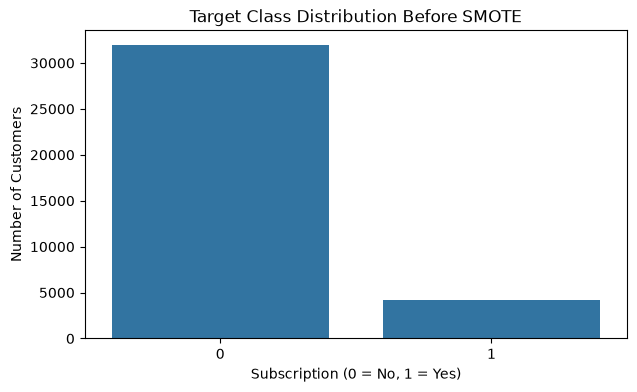

In [7]:
# Check target class distribution

print("Training Target Distribution:")
print(y_train.value_counts())

print("\nTraining Target Percentage:")
print(y_train.value_counts(normalize=True) * 100)

# Visualize class distribution
plt.figure(figsize=(7, 4))

sns.countplot(x=y_train)

plt.title("Target Class Distribution Before SMOTE")
plt.xlabel("Subscription (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

Apply SMOTE to training data

In [10]:
#Apply SMOTE to training data only

from imblearn.over_sampling import SMOTE

# Create SMOTE object
smote = SMOTE(random_state=42)

# Apply SMOTE to training data
X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

# Check class distribution after SMOTE
print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print("\nOriginal Training Shape:", X_train.shape)
print("Balanced Training Shape:", X_train_smote.shape)

Before SMOTE:
y
0    31937
1     4231
Name: count, dtype: int64

After SMOTE:
y
0    31937
1    31937
Name: count, dtype: int64

Original Training Shape: (36168, 51)
Balanced Training Shape: (63874, 51)


Train optimized Logistic Regression

In [11]:
#Train Logistic Regression with SMOTE

lr_smote = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train on balanced training data
lr_smote.fit(X_train_smote, y_train_smote)

# Predictions
lr_smote_train_pred = lr_smote.predict(X_train_smote)
lr_smote_test_pred = lr_smote.predict(X_test)

# Evaluate accuracy
print("Training Accuracy:",
      accuracy_score(y_train_smote, lr_smote_train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, lr_smote_test_pred))

Training Accuracy: 0.7144847668848044
Testing Accuracy: 0.7552803273250027


In [12]:
# Classification report after SMOTE

print("Logistic Regression with SMOTE")
print(classification_report(y_test, lr_smote_test_pred))

Logistic Regression with SMOTE
              precision    recall  f1-score   support

           0       0.94      0.77      0.85      7985
           1       0.27      0.63      0.38      1058

    accuracy                           0.76      9043
   macro avg       0.60      0.70      0.61      9043
weighted avg       0.86      0.76      0.79      9043



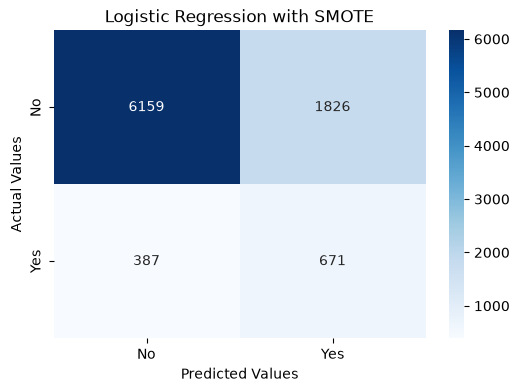

In [13]:
# Confusion Matrix

cm_lr_smote = confusion_matrix(y_test, lr_smote_test_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lr_smote,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Logistic Regression with SMOTE")
plt.show()

In [15]:
# Calculate SMOTE Logistic Regression metrics

lr_smote_results = {
    "Model": "Logistic Regression (SMOTE)",
    "Training Accuracy": accuracy_score(y_train_smote, lr_smote_train_pred),
    "Testing Accuracy": accuracy_score(y_test, lr_smote_test_pred),
    "Precision": precision_score(y_test, lr_smote_test_pred, zero_division=0),
    "Recall": recall_score(y_test, lr_smote_test_pred, zero_division=0),
    "F1 Score": f1_score(y_test, lr_smote_test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(
        y_test,
        lr_smote.predict_proba(X_test)[:, 1]
    )
}

print(pd.Series(lr_smote_results))

Model                Logistic Regression (SMOTE)
Training Accuracy                       0.714485
Testing Accuracy                         0.75528
Precision                               0.268722
Recall                                  0.634216
F1 Score                                0.377496
ROC-AUC                                 0.770058
dtype: object


In [16]:
# Train Random Forest with SMOTE

rf_smote = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train using balanced data
rf_smote.fit(X_train_smote, y_train_smote)

# Predictions
rf_smote_train_pred = rf_smote.predict(X_train_smote)
rf_smote_test_pred = rf_smote.predict(X_test)

# Accuracy
print("Training Accuracy:",
      accuracy_score(y_train_smote, rf_smote_train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, rf_smote_test_pred))

Training Accuracy: 1.0
Testing Accuracy: 0.8866526595156474


In [17]:
#  Classification Report

print("Random Forest with SMOTE")
print(classification_report(y_test, rf_smote_test_pred))

Random Forest with SMOTE
              precision    recall  f1-score   support

           0       0.91      0.96      0.94      7985
           1       0.53      0.32      0.40      1058

    accuracy                           0.89      9043
   macro avg       0.72      0.64      0.67      9043
weighted avg       0.87      0.89      0.87      9043



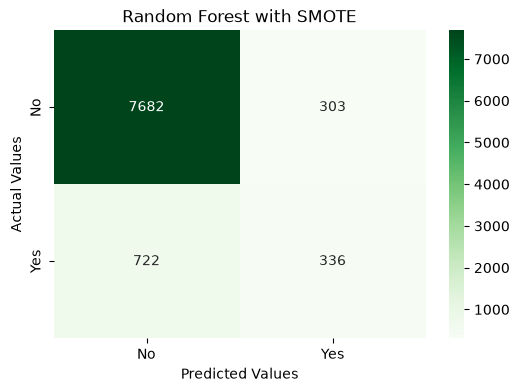

In [18]:
# Confusion Matrix

cm_rf_smote = confusion_matrix(y_test, rf_smote_test_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf_smote,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Random Forest with SMOTE")
plt.show()

In [19]:
# Calculate Random Forest SMOTE metrics

rf_smote_results = {
    "Model": "Random Forest (SMOTE)",
    "Training Accuracy": accuracy_score(
        y_train_smote, rf_smote_train_pred
    ),
    "Testing Accuracy": accuracy_score(
        y_test, rf_smote_test_pred
    ),
    "Precision": precision_score(
        y_test, rf_smote_test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, rf_smote_test_pred, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, rf_smote_test_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, rf_smote.predict_proba(X_test)[:, 1]
    )
}

print(pd.Series(rf_smote_results))

Model                Random Forest (SMOTE)
Training Accuracy                      1.0
Testing Accuracy                  0.886653
Precision                         0.525822
Recall                             0.31758
F1 Score                          0.395993
ROC-AUC                           0.781706
dtype: object


In [20]:
#Compare SMOTE Models

smote_comparison = pd.DataFrame([
    lr_smote_results,
    rf_smote_results
])

# Sort models by F1 Score
smote_comparison = smote_comparison.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

# Display comparison
display(smote_comparison.round(4))

,Model,Training Accuracy,Testing Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest (SMOTE),1.0000,0.8867,0.5258,0.3176,0.3960,0.7817
1,Logistic Regression (SMOTE),0.7145,0.7553,0.2687,0.6342,0.3775,0.7701


In [21]:
# Step 21: Random Forest Hyperparameter Tuning

from sklearn.model_selection import RandomizedSearchCV

# Define parameter combinations
rf_param_grid = {
    "n_estimators": [100, 150, 200],
    "max_depth": [10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

# Create Random Forest model
rf_tuning = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Randomized Search
rf_random_search = RandomizedSearchCV(
    estimator=rf_tuning,
    param_distributions=rf_param_grid,
    n_iter=10,
    cv=3,
    scoring="f1",
    verbose=2,
    random_state=42,
    n_jobs=-1
)

# Fit on SMOTE-balanced training data
rf_random_search.fit(X_train_smote, y_train_smote)

print("Best Parameters:")
print(rf_random_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(rf_random_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters:
{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': None}

Best Cross-Validation F1 Score:
0.9106229103671352


In [23]:
#  Display Best Random Forest Parameters

print("Best Hyperparameters:")
for parameter, value in rf_random_search.best_params_.items():
    print(f"{parameter}: {value}")

print("\nBest Cross-Validation F1 Score:",
      round(rf_random_search.best_score_, 4))

print("\nBest Cross-Validation F1 Percentage:",
      round(rf_random_search.best_score_ * 100, 2), "%")

Best Hyperparameters:
n_estimators: 100
min_samples_split: 5
min_samples_leaf: 2
max_features: log2
max_depth: None

Best Cross-Validation F1 Score: 0.9106

Best Cross-Validation F1 Percentage: 91.06 %


In [24]:
# Get the best Random Forest model

best_rf_model = rf_random_search.best_estimator_

print("Optimized Random Forest Model:")
print(best_rf_model)

Optimized Random Forest Model:
RandomForestClassifier(max_features='log2', min_samples_leaf=2,
                       min_samples_split=5, n_jobs=-1, random_state=42)


In [25]:
# Predictions using the optimized Random Forest model

best_rf_test_pred = best_rf_model.predict(X_test)

print("Optimized Random Forest - Test Results")

print("Accuracy:",
      accuracy_score(y_test, best_rf_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, best_rf_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, best_rf_test_pred))

Optimized Random Forest - Test Results
Accuracy: 0.8835563419219286

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.95      0.94      7985
           1       0.50      0.35      0.41      1058

    accuracy                           0.88      9043
   macro avg       0.71      0.65      0.67      9043
weighted avg       0.87      0.88      0.87      9043


Confusion Matrix:
[[7619  366]
 [ 687  371]]


In [26]:
# Final evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Get prediction probabilities for ROC-AUC
best_rf_test_proba = best_rf_model.predict_proba(X_test)[:, 1]

# Calculate metrics
final_results = {
    "Model": "Optimized Random Forest",
    "Accuracy": accuracy_score(y_test, best_rf_test_pred),
    "Precision": precision_score(y_test, best_rf_test_pred, zero_division=0),
    "Recall": recall_score(y_test, best_rf_test_pred, zero_division=0),
    "F1 Score": f1_score(y_test, best_rf_test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, best_rf_test_proba)
}

# Display results
final_results_df = pd.DataFrame([final_results])

display(final_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Optimized Random Forest,0.8836,0.5034,0.3507,0.4134,0.7926


In [29]:
# Compare Random Forest models

rf_final_comparison = pd.DataFrame([
    {
        "Model": "Baseline Random Forest",
        "Accuracy": accuracy_score(y_test, rf_test_pred),
        "Precision": precision_score(y_test, rf_test_pred, zero_division=0),
        "Recall": recall_score(y_test, rf_test_pred, zero_division=0),
        "F1 Score": f1_score(y_test, rf_test_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(
            y_test, baseline_models["random_forest"].predict_proba(X_test)[:, 1]
        )
    },
    rf_smote_results,
    {
        "Model": "Optimized Random Forest",
        "Accuracy": final_results["Accuracy"],
        "Precision": final_results["Precision"],
        "Recall": final_results["Recall"],
        "F1 Score": final_results["F1 Score"],
        "ROC-AUC": final_results["ROC-AUC"]
    }
])

display(
    rf_final_comparison
    .sort_values(by="F1 Score", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Accuracy,Testing Accuracy
0,Optimized Random Forest,0.8836,0.5034,0.3507,0.4134,0.7926,NaN,NaN
1,Random Forest (SMOTE),NaN,0.5258,0.3176,0.3960,0.7817,1.0,0.8867
2,Baseline Random Forest,0.8933,0.6154,0.2344,0.3395,0.7890,NaN,NaN


In [31]:
# Save the final optimized model

import joblib

# Save optimized Random Forest model
joblib.dump(
    best_rf_model,
    "../models/best_bank_campaign_model.pkl"
)

print("Final model saved successfully!")
print("File: models/best_bank_campaign_model.pkl")

Final model saved successfully!
File: models/best_bank_campaign_model.pkl


In [32]:
# Verify saved model

import joblib
import os

model_path = "../models/best_bank_campaign_model.pkl"

# Check whether file exists
if os.path.exists(model_path):
    print("Model file exists!")

    # Load saved model
    loaded_model = joblib.load(model_path)

    print("Model loaded successfully!")

    # Test prediction
    sample_prediction = loaded_model.predict(X_test.iloc[:5])

    print("\nSample Predictions:")
    print(sample_prediction)

else:
    print("Model file not found!")

Model file exists!
Model loaded successfully!

Sample Predictions:
[0 0 0 0 0]


In [33]:
# Save final model comparison report

report_path = "../reports/final_model_comparison.csv"

rf_final_comparison.to_csv(report_path, index=False)

print("Final model comparison report saved successfully!")
print("Location: reports/final_model_comparison.csv")

Final model comparison report saved successfully!
Location: reports/final_model_comparison.csv


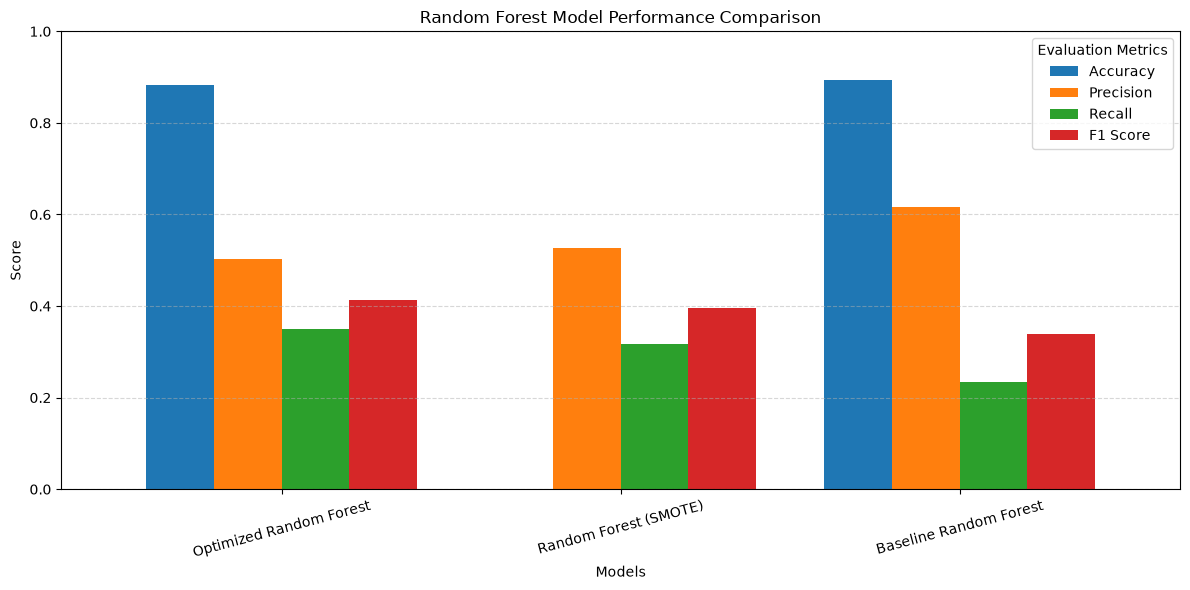

In [34]:
# Final model comparison visualization

import matplotlib.pyplot as plt
import seaborn as sns

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

comparison_plot = rf_final_comparison.set_index("Model")[metrics]

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Random Forest Model Performance Comparison")
plt.xlabel("Models")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

# Save figure
plt.savefig(
    "../reports/figures/final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

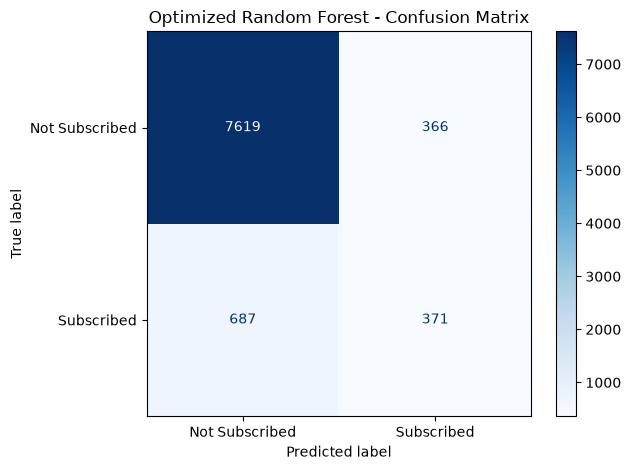

In [35]:
# Confusion Matrix for Optimized Random Forest

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, best_rf_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Subscribed", "Subscribed"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Optimized Random Forest - Confusion Matrix")
plt.tight_layout()

# Save confusion matrix
plt.savefig(
    "../reports/figures/optimized_rf_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

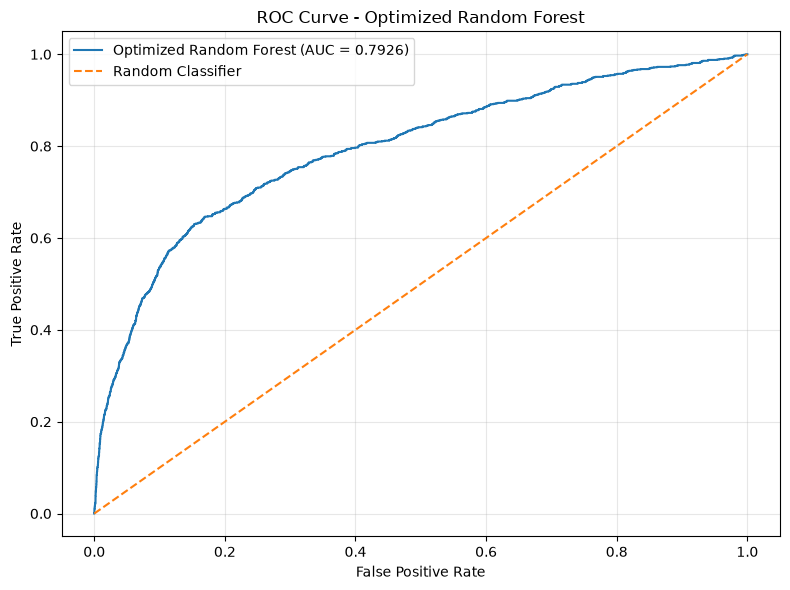

In [36]:
# ROC Curve for Optimized Random Forest

from sklearn.metrics import roc_curve, auc

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(
    y_test,
    best_rf_test_proba
)

roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Optimized Random Forest (AUC = {roc_auc:.4f})"
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Optimized Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure
plt.savefig(
    "../reports/figures/optimized_rf_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
# Save optimized model evaluation metrics

final_metrics_df = pd.DataFrame([final_results])

final_metrics_df.to_csv(
    "../reports/optimized_model_metrics.csv",
    index=False
)

print("Optimized model metrics saved successfully!")
print(final_metrics_df.round(4))

Optimized model metrics saved successfully!
                     Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Optimized Random Forest    0.8836     0.5034  0.3507    0.4134   0.7926


In [38]:
# Save optimized model hyperparameters

import json

best_parameters = rf_random_search.best_params_

with open(
    "../reports/best_model_parameters.json",
    "w"
) as file:
    json.dump(best_parameters, file, indent=4)

print("Best model parameters saved successfully!")

print("\nOptimized Hyperparameters:")
for parameter, value in best_parameters.items():
    print(f"{parameter}: {value}")

Best model parameters saved successfully!

Optimized Hyperparameters:
n_estimators: 100
min_samples_split: 5
min_samples_leaf: 2
max_features: log2
max_depth: None


In [39]:
# Create Sprint 3 summary report

summary = f"""
BANK MARKETING CAMPAIGN PREDICTION
SPRINT 3 - MODEL OPTIMIZATION AND FINAL EVALUATION

Final Selected Model: Optimized Random Forest

MODEL PERFORMANCE
-----------------
Accuracy  : {final_results['Accuracy']:.4f}
Precision : {final_results['Precision']:.4f}
Recall    : {final_results['Recall']:.4f}
F1 Score  : {final_results['F1 Score']:.4f}
ROC-AUC   : {final_results['ROC-AUC']:.4f}

OPTIMIZED HYPERPARAMETERS
-------------------------
{best_parameters}

SMOTE
-----
Applied only to training data.
Original test data remained unchanged.

MODEL FILE
----------
models/best_bank_campaign_model.pkl

EVALUATION REPORTS
------------------
reports/final_model_comparison.csv
reports/optimized_model_metrics.csv
reports/best_model_parameters.json

VISUALIZATIONS
--------------
reports/figures/final_model_comparison.png
reports/figures/optimized_rf_confusion_matrix.png
reports/figures/optimized_rf_roc_curve.png
"""

with open("../reports/sprint3_summary.txt", "w") as file:
    file.write(summary)

print("Sprint 3 summary report created successfully!")
print(summary)

Sprint 3 summary report created successfully!

BANK MARKETING CAMPAIGN PREDICTION
SPRINT 3 - MODEL OPTIMIZATION AND FINAL EVALUATION

Final Selected Model: Optimized Random Forest

MODEL PERFORMANCE
-----------------
Accuracy  : 0.8836
Precision : 0.5034
Recall    : 0.3507
F1 Score  : 0.4134
ROC-AUC   : 0.7926

OPTIMIZED HYPERPARAMETERS
-------------------------
{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': None}

SMOTE
-----
Applied only to training data.
Original test data remained unchanged.

MODEL FILE
----------
models/best_bank_campaign_model.pkl

EVALUATION REPORTS
------------------
reports/final_model_comparison.csv
reports/optimized_model_metrics.csv
reports/best_model_parameters.json

VISUALIZATIONS
--------------
reports/figures/final_model_comparison.png
reports/figures/optimized_rf_confusion_matrix.png
reports/figures/optimized_rf_roc_curve.png

